## Libraries ##

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import networkx as nx
import matplotlib.pyplot as plt
import scipy.linalg as la
import tqdm as tqdm

In [2]:
import numpy as np

def laplacian(A):
    """
    Compute the symmetrized normalized Laplacian of an adjacency matrix.

    Parameters
    ----------
    A : numpy.ndarray
        Adjacency matrix (n x n), assumed to be non-negative and symmetric.

    Returns
    -------
    L : numpy.ndarray
        Symmetrized normalized Laplacian matrix.
    """
    # Ensure A is a NumPy array
    A = np.asarray(A, dtype=float)

    # Degree vector
    degrees = A.sum(axis=1)

    # Inverse square root of degrees (handle zero degrees safely)
    with np.errstate(divide='ignore'):
        d_inv_sqrt = 1.0 / np.sqrt(degrees)
    d_inv_sqrt[np.isinf(d_inv_sqrt)] = 0.0

    # Construct D^{-1/2}
    D_inv_sqrt = np.diag(d_inv_sqrt)

    # Identity matrix
    I = np.eye(A.shape[0])

    # Symmetrized normalized Laplacian
    L = I - D_inv_sqrt @ A @ D_inv_sqrt

    return L


## Data Reader ##

In [3]:
data = np.load("network_ensembles.npz", allow_pickle=True)

A_er  = data["A_er"]
A_ws  = data["A_ws"]
A_ba  = data["A_ba"]
A_sbm = data["A_sbm"]
A_rg  = data["A_rg"]


N = A_ws[0].shape[0]
print(N)

100


## Biochemical dynamics ##

In [4]:
def biochemical(t, x, A, F, B, R):
    Ax = A @ x
    interaction = x * Ax
    return F - B * x - R * interaction

In [5]:
def thermo(t, U, J, dt, eps):

    # Liouville
    Udot = J @ U + U @ J.T
    U = U + dt * Udot

    # symmetry
    U = 0.5 * (U + U.T)
    U = U.real
    U = np.asarray(U, dtype=float)
    # spectral projection → density matrix
    w, V = la.eigh(U)
    w = np.maximum(w, eps)
    w = w / np.sum(w)
    rho = V @ np.diag(w) @ V.T

    log_rho = V @ np.diag(np.log(w)) @ V.T

    # entropy
    S = -np.sum(w * np.log(w))

    # symmetric generator
    D = 0.5 * (J + J.T)
    D = D.real

    D_r = V.T @ D @ V
    D_r = 0.5 * (D_r + D_r.T)

    Tr_rhoD = np.sum(w * np.diag(D_r))
    E = -2 * Tr_rhoD

    Tr_rhoD_logrho = np.sum(w * np.diag(D_r) * np.log(w))
    cov = Tr_rhoD_logrho + Tr_rhoD * S
    S_dot = -2 * cov



    return rho, S, S_dot

In [6]:
#Parameters and inital condition
F = 0.5
B = 0.1
R = 1
tf = 5
n_steps = 500
dt = tf / n_steps

np.random.seed(42)  # Set the seed
taus = np.linspace(dt, tf, n_steps)
x0 = np.random.rand(N)

ER

In [7]:
import os

outdir = "traj_bio_er"
os.makedirs(outdir, exist_ok=True)

for i in range(len(A_er)):
    sol_er = solve_ivp(
        biochemical,
        (dt, tf),
        x0,
        t_eval=taus,
        args=(A_er[i], F, B, R)
    )

    filename = os.path.join(outdir, f"traj_bio_er_{i:03d}.npz")
    np.savez(
        filename,
        t=sol_er.t,
        x=sol_er.y,
        A=A_er[i],
        F=F,
        B=B,
        R=R
    )



BA

In [8]:
import os

outdir = "traj_bio_ba"
os.makedirs(outdir, exist_ok=True)

for i in range(len(A_ba)):
    sol_ba = solve_ivp(
        biochemical,
        (dt, tf),
        x0,
        t_eval=taus,
        args=(A_ba[i], F, B, R)
    )

    filename = os.path.join(outdir, f"traj_bio_ba_{i:03d}.npz")
    np.savez(
        filename,
        t=sol_ba.t,
        x=sol_ba.y,
        A=A_ba[i],
        F=F,
        B=B,
        R=R
    )


SBM

In [9]:
import os

outdir = "traj_bio_sbm"
os.makedirs(outdir, exist_ok=True)

for i in range(len(A_sbm)):
    sol_sbm = solve_ivp(
        biochemical,
        (dt, tf),
        x0,
        t_eval=taus,
        args=(A_sbm[i], F, B, R)
    )

    filename = os.path.join(outdir, f"traj_bio_sbm_{i:03d}.npz")
    np.savez(
        filename,
        t=sol_sbm.t,
        x=sol_sbm.y,
        A=A_sbm[i],
        F=F,
        B=B,
        R=R
    )


## Thermodynamics functions ##

In [10]:
def jac_bio(t, x, A, B, R):
    Ax = A @ x
    I = np.eye(len(x))
    return -B * I - R * (Ax * I + x[:, None] * A)



## Results ##

### ER ###

Number of realizations: 100


Network realizations: 100%|██████████| 100/100 [3:15:23<00:00, 117.23s/it] 


Mean Δt: -2.8155999999999994
Std  Δt: 0.045985215015263294
Fraction Δt > 0: 0.0


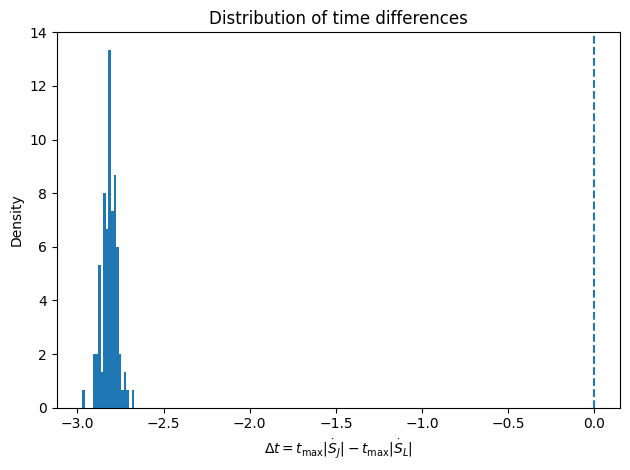

In [11]:
import os
import numpy as np
import scipy.linalg as la
import matplotlib.pyplot as plt
from tqdm import tqdm



eps = 1e-12


indir = "traj_bio_er"

files = sorted(f for f in os.listdir(indir) if f.endswith(".npz"))
print("Number of realizations:", len(files))


# ============================================================
# OUTPUT
# ============================================================
t_peak_J = []
t_peak_L = []



for fname in tqdm(files, desc="Network realizations"):

    
    data = np.load(os.path.join(indir, fname), allow_pickle=True)

    x_traj = data["x"]    # shape (N, T)
    A = data["A"]         # shape (N, N)

    N, T = x_traj.shape

    
    U_J = np.eye(N)
    U_L = np.eye(N)

    Sdot_J = np.zeros(T)
    Sdot_L = np.zeros(T)

    
    L = laplacian(A)


    for k in tqdm(range(T), desc="Time steps", leave=False):

        xk = x_traj[:, k]
        t = taus[k]

        
        J_dyn = jac_bio(t, xk, A, B, R)
        U_J, S_J, Sdot_J[k] = thermo(t, U_J, J_dyn, dt, eps)

        
        J_lap = -L
        U_L, S_L, Sdot_L[k] = thermo(t, U_L, J_lap, dt, eps)


    kJ = np.argmax(np.abs(Sdot_J))
    kL = np.argmax(np.abs(Sdot_L))

    t_peak_J.append(taus[kJ])
    t_peak_L.append(taus[kL])



t_peak_J = np.array(t_peak_J)
t_peak_L = np.array(t_peak_L)

delta_t = t_peak_J - t_peak_L



print("Mean Δt:", delta_t.mean())
print("Std  Δt:", delta_t.std())
print("Fraction Δt > 0:", np.mean(delta_t > 0))



plt.figure()
plt.hist(delta_t, bins=20, density=True)
plt.axvline(0.0, linestyle="--")
plt.xlabel(r"$\Delta t = t_{\max}|\dot S_J| - t_{\max}|\dot S_L|$")
plt.ylabel("Density")
plt.title("Distribution of time differences")
plt.tight_layout()
plt.show()


In [12]:
np.savez(
    "delta_t_bio_er.npz",
    delta_t=delta_t,
    t_peak_J=t_peak_J,
    t_peak_L=t_peak_L
)

### BA ###

Number of realizations: 100


Network realizations: 100%|██████████| 100/100 [3:15:14<00:00, 117.14s/it] 


Mean Δt: -2.9444
Std  Δt: 0.026993332510084806
Fraction Δt > 0: 0.0


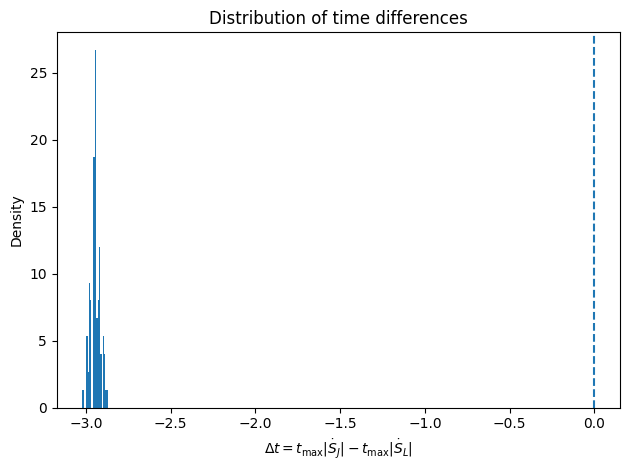

In [13]:
import os
import numpy as np
import scipy.linalg as la
import matplotlib.pyplot as plt
from tqdm import tqdm



eps = 1e-12


indir = "traj_bio_ba"

files = sorted(f for f in os.listdir(indir) if f.endswith(".npz"))
print("Number of realizations:", len(files))


# ============================================================
# OUTPUT
# ============================================================
t_peak_J = []
t_peak_L = []



for fname in tqdm(files, desc="Network realizations"):

    
    data = np.load(os.path.join(indir, fname), allow_pickle=True)

    x_traj = data["x"]    # shape (N, T)
    A = data["A"]         # shape (N, N)

    N, T = x_traj.shape

    
    U_J = np.eye(N)
    U_L = np.eye(N)

    Sdot_J = np.zeros(T)
    Sdot_L = np.zeros(T)

    
    L = laplacian(A)


    for k in tqdm(range(T), desc="Time steps", leave=False):

        xk = x_traj[:, k]
        t = taus[k]

        
        J_dyn = jac_bio(t, xk, A, B, R)
        U_J, S_J, Sdot_J[k] = thermo(t, U_J, J_dyn, dt, eps)

        
        J_lap = -L
        U_L, S_L, Sdot_L[k] = thermo(t, U_L, J_lap, dt, eps)


    kJ = np.argmax(np.abs(Sdot_J))
    kL = np.argmax(np.abs(Sdot_L))

    t_peak_J.append(taus[kJ])
    t_peak_L.append(taus[kL])



t_peak_J = np.array(t_peak_J)
t_peak_L = np.array(t_peak_L)

delta_t = t_peak_J - t_peak_L



print("Mean Δt:", delta_t.mean())
print("Std  Δt:", delta_t.std())
print("Fraction Δt > 0:", np.mean(delta_t > 0))



plt.figure()
plt.hist(delta_t, bins=20, density=True)
plt.axvline(0.0, linestyle="--")
plt.xlabel(r"$\Delta t = t_{\max}|\dot S_J| - t_{\max}|\dot S_L|$")
plt.ylabel("Density")
plt.title("Distribution of time differences")
plt.tight_layout()
plt.show()


In [14]:
np.savez(
    "delta_t_bio_ba.npz",
    delta_t=delta_t,
    t_peak_J=t_peak_J,
    t_peak_L=t_peak_L)

### SBM ###

Number of realizations: 100


Network realizations: 100%|██████████| 100/100 [3:15:23<00:00, 117.24s/it] 

Mean Δt: -2.4349
Std  Δt: 0.09905044169512825
Fraction Δt > 0: 0.0


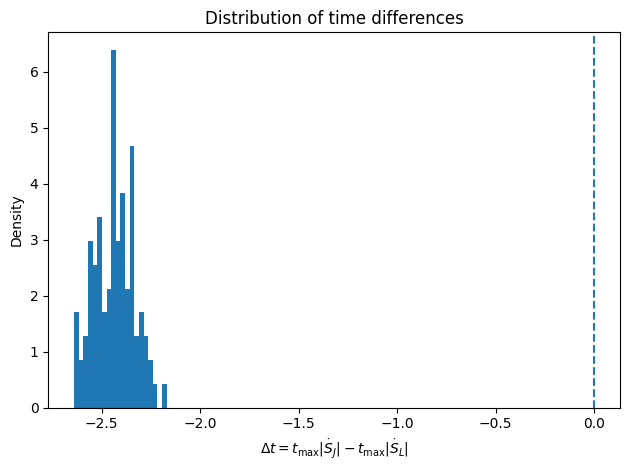

In [15]:
import os
import numpy as np
import scipy.linalg as la
import matplotlib.pyplot as plt
from tqdm import tqdm



eps = 1e-12


indir = "traj_bio_sbm"

files = sorted(f for f in os.listdir(indir) if f.endswith(".npz"))
print("Number of realizations:", len(files))



t_peak_J = []
t_peak_L = []



for fname in tqdm(files, desc="Network realizations"):

    
    data = np.load(os.path.join(indir, fname), allow_pickle=True)

    x_traj = data["x"]    # shape (N, T)
    A = data["A"]         # shape (N, N)

    N, T = x_traj.shape

    
    U_J = np.eye(N)
    U_L = np.eye(N)

    Sdot_J = np.zeros(T)
    Sdot_L = np.zeros(T)

    
    L = laplacian(A)

    
    for k in tqdm(range(T), desc="Time steps", leave=False):

        xk = x_traj[:, k]
        t = taus[k]

        
        J_dyn = jac_bio(t, xk, A, B, R)
        U_J, S_J, Sdot_J[k] = thermo(t, U_J, J_dyn, dt, eps)

        
        J_lap = -L
        U_L, S_L, Sdot_L[k] = thermo(t, U_L, J_lap, dt, eps)

    
    kJ = np.argmax(np.abs(Sdot_J))
    kL = np.argmax(np.abs(Sdot_L))

    t_peak_J.append(taus[kJ])
    t_peak_L.append(taus[kL])



t_peak_J = np.array(t_peak_J)
t_peak_L = np.array(t_peak_L)

delta_t = t_peak_J - t_peak_L



print("Mean Δt:", delta_t.mean())
print("Std  Δt:", delta_t.std())
print("Fraction Δt > 0:", np.mean(delta_t > 0))



plt.figure()
plt.hist(delta_t, bins=20, density=True)
plt.axvline(0.0, linestyle="--")
plt.xlabel(r"$\Delta t = t_{\max}|\dot S_J| - t_{\max}|\dot S_L|$")
plt.ylabel("Density")
plt.title("Distribution of time differences")
plt.tight_layout()
plt.show()

In [16]:
np.savez(
    "delta_t_bio_sbm.npz",
    delta_t=delta_t,
    t_peak_J=t_peak_J,
    t_peak_L=t_peak_L)